# Project : "Telecom - Churn Rate ML"
* Domain : Telecomunication 

# ML Model Building Path :
1. Define Business Case, Problem & Project Goal
2. Imports Laibrarys
3. Load and Validate the Data
4. 

# Business Case 
        "No-Churn Telecom is an established Telecom in Europe with more than a decade in Business. Due to new players in the market, telecom industry become very competitive and retaining customers becoming a challenge."

# Problem Statment 
        "In spite of No-Churn initiatives of reducing tariffs and promoting more offers, the churn rate ( percentage of customers migrating to competitors) is well above 10%."

# Project Goal 

* Understanding the variables that are influencing the customers to migrate.

* Creating Churn risk scores that can be indicative to drive retention campaigns.

* Introduce new predicting variable "CHURN-FLAG" with values YES(1) or NO(0) so that email campaigns with iucrative offers can be targeted to Churn YES customers.

# Imports Laibrarys 

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression, RidgeClassifier

# Load and Validate the Data

In [2]:
df = pd.read_csv("D:\\datasets\\Internship_Projects\\Client_Project\\shopping distribution according to gender.csv")
df.head()

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4.0,124962.0,44.0,45.0,-361.0,0.0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2.0,130556.0,62.0,39.0,5973.0,0.0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0.0,148828.0,49.0,24.0,193.0,1.0
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1.0,38722.0,80.0,25.0,9377.0,1.0
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2.0,55098.0,78.0,15.0,1393.0,0.0


In [3]:
# Select numerical columns
df.select_dtypes(include=['int64', 'float64']).columns

Index(['customer_id', 'age', 'pincode', 'num_dependents', 'estimated_salary',
       'calls_made', 'sms_sent', 'data_used', 'churn'],
      dtype='str')

In [4]:
# Select categorical columns
df.select_dtypes(include=['object']).columns

Index(['telecom_partner', 'gender', 'state', 'city', 'date_of_registration'], dtype='str')

In [5]:
# Dataset Shape
df.shape

(184209, 14)

In [6]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [7]:
# Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 184209 entries, 0 to 184208
Data columns (total 14 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   customer_id           184209 non-null  int64  
 1   telecom_partner       184209 non-null  str    
 2   gender                184209 non-null  str    
 3   age                   184209 non-null  int64  
 4   state                 184209 non-null  str    
 5   city                  184209 non-null  str    
 6   pincode               184209 non-null  int64  
 7   date_of_registration  184209 non-null  str    
 8   num_dependents        184208 non-null  float64
 9   estimated_salary      184208 non-null  float64
 10  calls_made            184208 non-null  float64
 11  sms_sent              184208 non-null  float64
 12  data_used             184208 non-null  float64
 13  churn                 184208 non-null  float64
dtypes: float64(6), int64(3), str(5)
memory usage: 19.7 MB


In [8]:
# Dataset Description
df.describe(include='all')

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
count,184209.000000,184209,184209,184209.000000,184209,184209,184209.000000,184209,184208.000000,184208.000000,184208.000000,184208.000000,184208.000000,184208.000000
unique,NaN,4,2,NaN,28,6,NaN,923,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Reliance Jio,M,NaN,Karnataka,Hyderabad,NaN,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,46231,110304,NaN,6722,30819,NaN,200,NaN,NaN,NaN,NaN,NaN,NaN
mean,92105.000000,NaN,NaN,46.089996,NaN,NaN,549655.250417,NaN,1.996504,85033.173038,48.957309,23.952586,4990.401850,0.200567
std,53176.702206,NaN,NaN,16.436551,NaN,NaN,259787.686919,NaN,1.414474,37542.322288,29.441515,14.727613,2942.835665,0.400426
min,1.000000,NaN,NaN,18.000000,NaN,NaN,100006.000000,NaN,0.000000,20001.000000,-10.000000,-5.000000,-987.000000,0.000000
25%,46053.000000,NaN,NaN,32.000000,NaN,NaN,324608.000000,NaN,1.000000,52511.750000,24.000000,11.000000,2488.000000,0.000000
50%,92105.000000,NaN,NaN,46.000000,NaN,NaN,548212.000000,NaN,2.000000,85040.500000,49.000000,24.000000,4984.000000,0.000000
75%,138157.000000,NaN,NaN,60.000000,NaN,NaN,775187.000000,NaN,3.000000,117617.250000,74.000000,37.000000,7491.000000,0.000000


In [9]:
# Check the number of unique values in each column
df.nunique()

customer_id             184209
telecom_partner              4
gender                       2
age                         57
state                       28
city                         6
pincode                 166636
date_of_registration       923
num_dependents               5
estimated_salary         98472
calls_made                 119
sms_sent                    59
data_used                11789
churn                        2
dtype: int64

In [10]:
# Check for missing values
df.isnull().sum()[df.isnull().sum()>0]

num_dependents      1
estimated_salary    1
calls_made          1
sms_sent            1
data_used           1
churn               1
dtype: int64

In [11]:
# Check the distribution of the target variable
print("Not Churned:", df['churn'].value_counts().iloc[0])
print("Churned:", df['churn'].value_counts().iloc[1])

Not Churned: 147262
Churned: 36946


# Data Cleaning :

In [12]:
df.isnull().sum()[df.isnull().sum()>0]

num_dependents      1
estimated_salary    1
calls_made          1
sms_sent            1
data_used           1
churn               1
dtype: int64

In [13]:
# Drop Customer_id from original Data

df.drop(columns=['customer_id'],inplace=True)

In [14]:
df['num_dependents'] = df['num_dependents'].fillna(df['num_dependents'].median())
df['estimated_salary'] = df['estimated_salary'].fillna(df['estimated_salary'].median())
df['calls_made'] = df['calls_made'].fillna(df['calls_made'].median())
df['sms_sent'] = df['sms_sent'].fillna(df['sms_sent'].median())
df['data_used'] = df['data_used'].fillna(df['data_used'].median())

In [15]:
# 
df = df.dropna(subset=['churn'])

In [19]:
df.isnull().sum()[df.isnull().sum()>0]

Series([], dtype: int64)

# Exploratry Data Analysis (EDA) 

# Heatmape :
Correlation of Veriables 

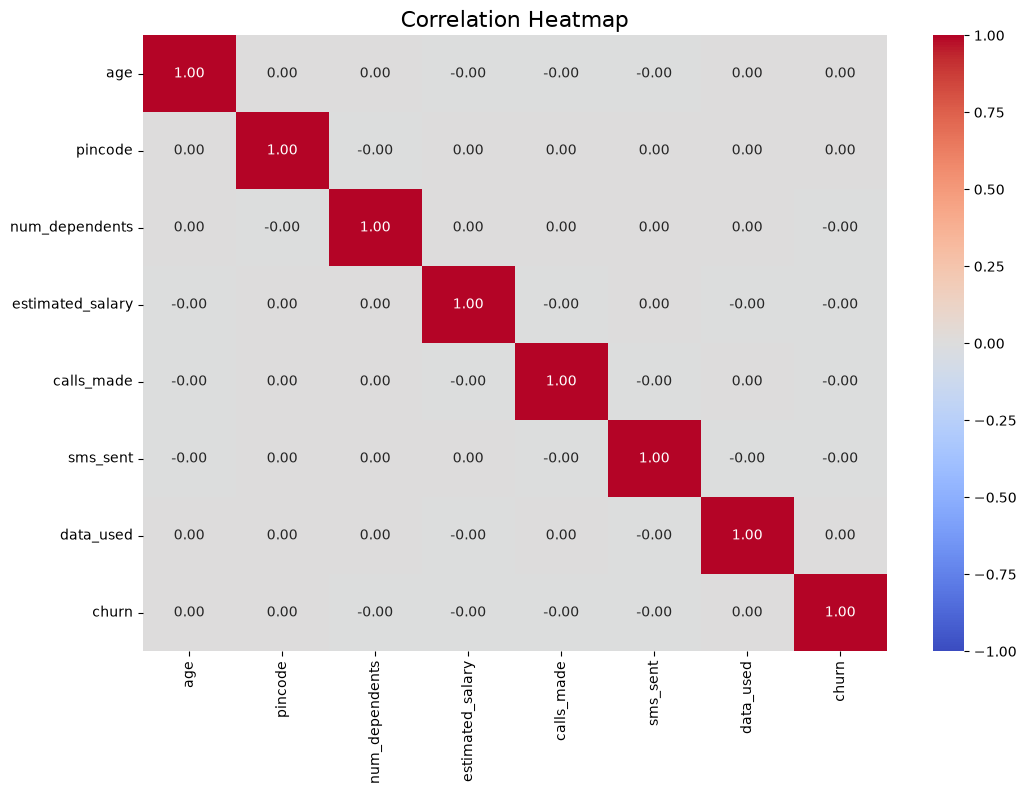

In [16]:
# Heatmape of Correlation Matrix
numerical_cols = ['age', 'pincode', 'num_dependents', 'estimated_salary',
       'calls_made', 'sms_sent', 'data_used', 'churn']
plt.figure(figsize=(12,8))
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Heatmap", fontsize=16)
plt.show()

# Bar Plot :
Customer Churn Distribution 

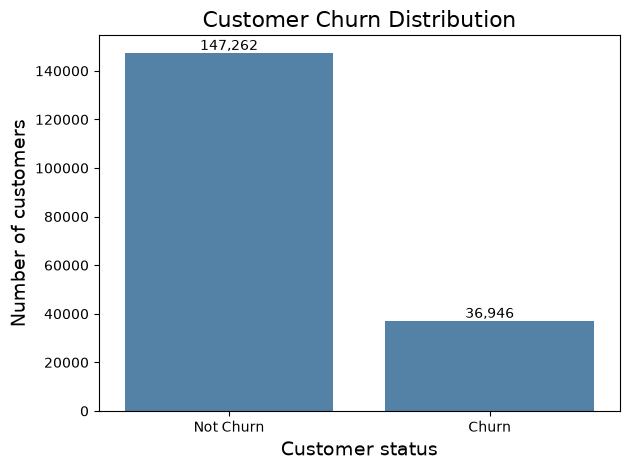

In [17]:
# Count each class, keeping both categories even if one has no rows
churn_counts = (
    df["churn"]
    .map({0: "Not Churn", 1: "Churn"})
    .value_counts()
    .reindex(["Not Churn", "Churn"], fill_value=0)
)

ax = sns.barplot(x=churn_counts.index, y=churn_counts.values, color="steelblue")

# Show counts above the bars
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

ax.set_title("Customer Churn Distribution", fontsize=16)
ax.set_xlabel("Customer status", fontsize=14)
ax.set_ylabel("Number of customers", fontsize=14)
plt.tight_layout()
plt.show()

# Customer Distribution by Telecom Partner

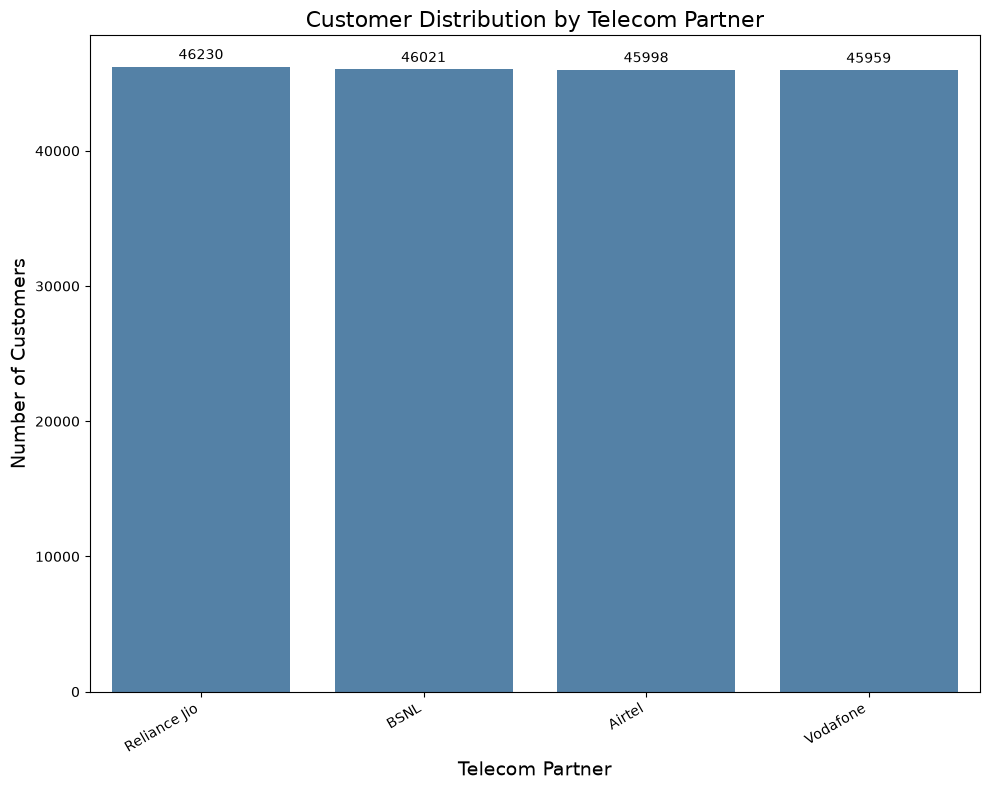

In [18]:
partner_counts = df["telecom_partner"].value_counts()

plt.figure(figsize=(10, 8))
ax = sns.barplot(
    x=partner_counts.index,
    y=partner_counts.values,
    color="steelblue"
)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_title("Customer Distribution by Telecom Partner",fontsize=16)
ax.set_xlabel("Telecom Partner",fontsize=14)
ax.set_ylabel("Number of Customers",fontsize=14)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()